In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
df=pd.read_csv(r"D:\ML\emails.csv")

In [43]:
df

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5167,Email 5168,2,2,2,3,0,0,32,0,0,...,0,0,0,0,0,0,0,0,0,0
5168,Email 5169,35,27,11,2,6,5,151,4,3,...,0,0,0,0,0,0,0,1,0,0
5169,Email 5170,0,0,1,1,0,0,11,0,0,...,0,0,0,0,0,0,0,0,0,1
5170,Email 5171,2,7,1,0,2,1,28,2,0,...,0,0,0,0,0,0,0,1,0,1


In [44]:
x=df.drop(['Email No.', 'Prediction'], axis =1)
y=df['Prediction']

In [45]:
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [46]:
sc=StandardScaler()
x_train_scaled=sc.fit_transform(x_train)
x_test_scaled=sc.transform(x_test)

In [47]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
knn_pred=knn.predict(x_test_scaled)

In [48]:
svm=SVC(kernel='rbf',random_state=42)
svm.fit(x_train_scaled, y_train)
svm_pred=svm.predict(x_test_scaled)

In [49]:
print(classification_report(y_test,knn_pred))
print(confusion_matrix(y_test,knn_pred))
print(accuracy_score(y_test,knn_pred))

              precision    recall  f1-score   support

           0       0.98      0.80      0.88       739
           1       0.66      0.95      0.78       296

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.83      1035
weighted avg       0.89      0.85      0.85      1035

[[593 146]
 [ 14 282]]
0.8454106280193237


In [50]:
print(classification_report(y_test,svm_pred))
print(confusion_matrix(y_test,svm_pred))
print(accuracy_score(y_test,svm_pred))

              precision    recall  f1-score   support

           0       0.93      1.00      0.96       739
           1       1.00      0.82      0.90       296

    accuracy                           0.95      1035
   macro avg       0.96      0.91      0.93      1035
weighted avg       0.95      0.95      0.95      1035

[[738   1]
 [ 54 242]]
0.9468599033816425


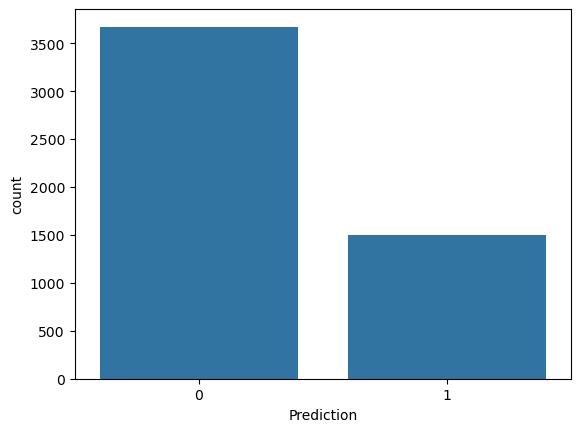

In [51]:
sns.countplot(x=y)
plt.show()

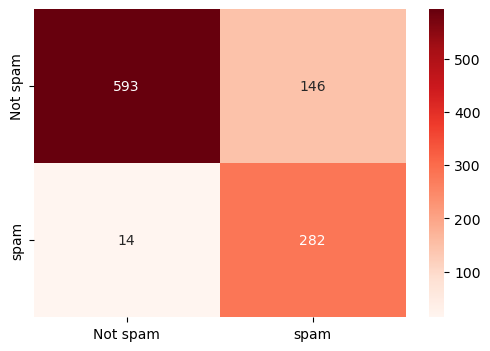

In [57]:
plt.figure(figsize=(6,4))

sns.heatmap(
    confusion_matrix(y_test,knn_pred),
    annot=True,
    fmt="d",
    cmap="Reds",
    yticklabels=["Not spam","spam"],
    xticklabels=["Not spam","spam"]
)
plt.show()


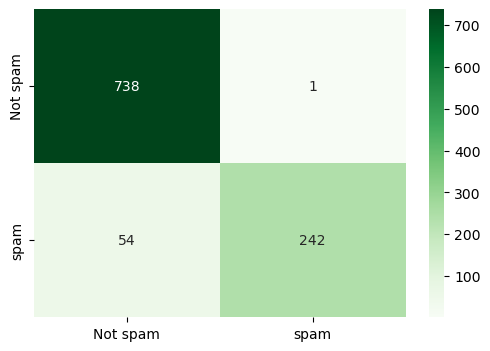

In [59]:
plt.figure(figsize=(6,4))

sns.heatmap(
    confusion_matrix(y_test,svm_pred),
    annot=True,
    fmt="d",
    cmap="Greens",
    yticklabels=["Not spam","spam"],
    xticklabels=["Not spam","spam"]
)
plt.show()